# AI651 Assignment 3 — Q4 & Q5: spatio-temporal forecasting and fixed / learnable / hybrid adjacency
**Student:** Huzaifa | **Roll No:** 25280009 | AI651 Deep Learning for Space, Time and Graphs, Fall 2026, Assignment 3

This notebook (i) builds the forecasting windows (Q4(a)), (ii) trains the temporal-only baseline (Q4(c)) and the STGNN with **fixed** (Q5(a)), **adaptive** (Q5(b)) and **hybrid** (Q5(c)) adjacency under one identical protocol, and (iii) saves every metric, training time, checkpoint, prediction and learned graph for `Q6_analysis.ipynb`.
Prerequisite: `Q3_data_and_graph.ipynb` must have been run (it writes `data/processed/*`).

In [1]:
import os, sys, time, json
sys.path.insert(0, '../src')
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from common import set_seed, hardware_info, save_json, PROC, RES, FIG, CKPT, SEED
from data import build_data, T_IN, T_OUT, N_NODES, split_slices, load_processed
from models import STModel, AdaptiveAdjacency, fixed_adjacency, count_params
from train import CFG, train_model, evaluate, predict, metrics_from
import warnings; warnings.filterwarnings('ignore', category=FutureWarning)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
set_seed(SEED); print('Global seed =', SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
HW = hardware_info(); save_json(HW, f'{RES}/hardware.json'); print(json.dumps(HW, indent=1)); print('training device:', DEVICE)
print('CONFIG:', json.dumps(CFG, indent=1))

/home/huzaifa/miniconda3/envs/pa1/lib/python3.11/site-packages/torch/cuda/__init__.py:58: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Global seed = 42


{
 "cpu_model": "Intel(R) Core(TM) i7-14650HX",
 "cpu_physical_cores": 12,
 "cpu_logical_cores": 24,
 "ram_gb": 15.5,
 "os": "Linux-5.15.167.4-microsoft-standard-WSL2-x86_64-with-glibc2.39",
 "python": "3.11.17",
 "torch": "2.4.1+cu124",
 "numpy": "2.4.6",
 "cuda_available": true,
 "gpu": "NVIDIA GeForce RTX 4060 Laptop GPU",
 "gpu_memory_gb": 8.0,
 "cuda_version": "12.4",
 "pandas": "3.0.6",
 "h5py": "3.16.0",
 "matplotlib": "3.11.2",
 "sklearn": "1.9.1"
}
training device: cuda
CONFIG: {
 "seed": 42,
 "batch_size": 64,
 "lr": 0.001,
 "weight_decay": 0.0,
 "max_epochs": 60,
 "patience": 6,
 "min_delta": 0.0,
 "grad_clip": 5.0,
 "hidden_d": 32,
 "head_hidden": 64,
 "d_e": 10,
 "top_k": 20,
 "loss": "masked MAE, weighted by sensor std (= raw-unit MAE / global std)",
 "norm": "per-sensor z-score (train only)"
}


## Q4(a) — Forecasting windows, chronological splits, normalisation
* Input $X_t=[x_{t-7},\dots,x_t]\in\mathbb R^{8\times716\times1}$, target $Y_t=[x_{t+1},\dots,x_{t+4}]\in\mathbb R^{4\times716\times1}$ (15-min steps: 2 h of history → next hour).
* Splits (chronological, on the 15-min axis): **train** Jan–Dec 2020, **validation** Jan–Mar 2021, **test** Apr–Dec 2021.
* Windows are generated **inside each split segment only**, so the first input row and the last target row of every window lie in the same split (a window never straddles a boundary). The code asserts this and an exhaustive check over *all* windows is run below. Number of windows per split $=L-11$ with $L$ the rows of the split.
* **Z-score normalisation (per sensor, train-only):** for every sensor the mean and std are computed **only over the observed values of the training split (2020)** and applied to all splits (sensors with < 1000 training observations — the 19 sensors that have no 2020 data — use the global training mean/std); predictions are inverted (×std_j+mean_j) before every metric. *Design note (documented iteration):* my first attempt used one global scalar mean/std; with that choice the fixed-graph STGNN reached validation MAE 121.3 vs 56.5 for the temporal-only model (results kept in `results/iter1_global_norm/`) because graph averaging mixes sensors whose flow levels differ by a factor of 40 (per-sensor mean 30–1264). Per-sensor normalisation fixes the scale mismatch and also helps the temporal-only model; it is a data-preparation choice made on **validation** results only, and all four models use it.
* **Loss weighting:** the MAE loss is computed as |error| × (std_j / global std) so that, although each sensor is normalised separately, the loss equals the raw-unit MAE (divided by the global std) that is actually reported.
* **Batch size 64:** 549 optimisation steps per epoch on 35,125 training windows — enough gradient noise/steps per epoch for fast early stopping, while one step already processes 64×716 = 45,824 sensor series, so memory is small (≈ 0.5 GB) and larger batches would only reduce the number of updates; 64 is also the LargeST benchmark default.

In [2]:
data = build_data(batch_size=CFG['batch_size'], seed=SEED)
sets, sl, times = data['sets'], data['slices'], data['times']
# exhaustive boundary check over every window of every split
chk = {}
for k, s in sets.items():
    lo, hi = sl[k]
    first_in = np.array([s.anchor(i) - (T_IN - 1) for i in range(len(s))]); last_tgt = np.array([s.anchor(i) + T_OUT for i in range(len(s))])
    assert first_in.min() >= lo and last_tgt.max() < hi and (last_tgt - first_in == T_IN + T_OUT - 1).all()
    chk[k] = dict(windows=len(s), first_input_time=str(times[first_in.min()]), last_target_time=str(times[last_tgt.max()]), rows=int(hi - lo))
print(pd.DataFrame(chk).T.to_string())
assert sl['train'][1] == sl['val'][0] and sl['val'][1] == sl['test'][0]
x, y, m = next(iter(data['loaders']['train']))
print('one training batch: X', tuple(x.shape), '= (B, 8, N, 1) | Y', tuple(y.shape), '= (B, 4, N) | target-valid mask', tuple(m.shape))
print('batches per epoch (train/val/test):', {k: len(v) for k, v in data['loaders'].items()})
Q4a = dict(window_counts=data['counts'], splits=chk, norm='per-sensor z-score, train split only', global_mean=data['global_mean'], global_std=data['global_std'], sensor_mean_min=float(data['mean_np'].min()), sensor_mean_max=float(data['mean_np'].max()), sensor_std_min=float(data['std_np'].min()), sensor_std_max=float(data['std_np'].max()), batch_size=CFG['batch_size'],
           steps_per_epoch=len(data['loaders']['train']), input_shape=[8, 716, 1], target_shape=[4, 716, 1])
mean, std = data['mean'], data['std']

z-score mode=sensor (train split only, 24,107,001 observed values): global mean=607.75 std=483.49 | per-sensor mean range [29.5, 1264.5], std range [27.8, 788.9]
train: rows [0, 35136) 2020-01-01 00:00:00 -> 2020-12-31 23:45:00 | rows=35136 windows=35125
val  : rows [35136, 43776) 2021-01-01 00:00:00 -> 2021-03-31 23:45:00 | rows=8640 windows=8629
test : rows [43776, 70176) 2021-04-01 00:00:00 -> 2021-12-31 23:45:00 | rows=26400 windows=26389
      windows     first_input_time     last_target_time   rows
train   35125  2020-01-01 00:00:00  2020-12-31 23:45:00  35136
val      8629  2021-01-01 00:00:00  2021-03-31 23:45:00   8640
test    26389  2021-04-01 00:00:00  2021-12-31 23:45:00  26400
one training batch: X (64, 8, 716, 1) = (B, 8, N, 1) | Y (64, 4, 716) = (B, 4, N) | target-valid mask (64, 4, 716)
batches per epoch (train/val/test): {'train': 549, 'val': 135, 'test': 413}


### Reference point: "historical last" (persistence) baseline — not a trained model
Predict $\hat x_{t+h}=x_t$ for all four horizons, evaluated with exactly the same masked, de-normalised metric on the validation and test windows. It is shown only to put the learned models' errors in context.

In [3]:
def persistence_metrics(split):
    P, Y, M = [], [], []
    for x, y, m in data['loaders'][split]:
        last = x[:, -1, :, 0]                                          # (B, N) normalised last observed (possibly imputed) value
        P.append((last.unsqueeze(1).repeat(1, T_OUT, 1)) * std + mean); Y.append(y * std + mean); M.append(m)
    return metrics_from(torch.cat(P), torch.cat(Y), torch.cat(M))
HL = {s: persistence_metrics(s) for s in ('val', 'test')}
for s in HL: print('Historical-last  %-4s MAE %.2f RMSE %.2f | per-horizon MAE %s' % (s, HL[s]['mae'], HL[s]['rmse'], np.round(HL[s]['mae_h'], 2)))

Historical-last  val  MAE 81.28 RMSE 125.27 | per-horizon MAE [ 49.39  70.81  91.79 113.13]
Historical-last  test MAE 87.18 RMSE 132.99 | per-horizon MAE [ 52.73  75.93  98.65 121.42]


## Q4(b) — Model definition (shared by all four runs)
**Shapes.** `x: (B, 8, N, 1)` → temporal encoder → `Z: (B, N, d)` → graph conv `H = ReLU(Â Z W_g)` → head → `Ŷ: (B, 4, N)` (the size-1 feature axis F is squeezed; targets are stored as `(B, 4, N)` too).
1. **Temporal encoder** (`models.TemporalEncoder`): the 8-step series of every sensor is processed independently by two `Conv1d` layers (kernel 3, same padding, ReLU, 32 channels) followed by a linear read-out over (channels × time) → `d = 32` features per sensor. Implementation detail: `(B,8,N,1)` is reshaped to `(B·N, 1, 8)` so that the convolution acts along time for each sensor.
2. **Spatial graph convolution (exactly the assignment formula):** `H = ReLU( Â Z W_g )`, `W_g ∈ ℝ^{32×32}` (+bias). The product `Â Z` is `einsum('nm,bmd->bnd', Â, Z)`, i.e. a dense 716×716 matrix multiplied over the node axis separately for every batch element.
3. **Forecast head:** `Linear(32→64) → ReLU → Linear(64→4)` applied per sensor: the 4 outputs are the four 15-min horizons.
**Loss:** masked **MAE** (L1), weighted so that it equals the raw-unit MAE divided by the global std. MAE is recommended for traffic: flow data contain outages/spikes and heavy tails; L1 is robust to them and directly optimises the reported MAE. Only entries whose *target* is an observed value (mask = 1) enter the loss.
**Optimiser:** Adam, lr 1e-3, batch 64, gradient-norm clip 5, max 60 epochs, **early stopping on validation MAE** (patience 6), best-validation checkpoint restored for the final evaluation. Same for all four models.
**Metric convention (all models):** MAE/RMSE are computed in original units (vehicles per 15 min) **only over target entries that are observed** (not NaN-missing, not part of a ≥3 h outage; see Q3(a)). Genuine zeros that are observed are kept. Overall = all valid (window, horizon, sensor) entries; per-horizon = valid entries of that horizon.
**Temporal-only baseline (Q4(c)):** identical encoder and head; the graph layer is removed: `H = ReLU(Z)`.

In [4]:
A_raw = np.load(f'{PROC}/sd_adj.npy')
A_fixed = fixed_adjacency(A_raw, 'row')
print('fixed adjacency D_out^-1 (A+I): row sums in [%.6f, %.6f] | nnz %d | self-loop weight min/max %.3f/%.3f' % (
    A_fixed.sum(1).min(), A_fixed.sum(1).max(), int((A_fixed > 0).sum()), A_fixed.diag().min(), A_fixed.diag().max()))
def make(graph):
    set_seed(SEED)                                                  # identical initialisation of the shared layers
    return STModel(graph, N_NODES, d=CFG['hidden_d'], t_in=T_IN, horizon=T_OUT, A_fixed=A_fixed, d_e=CFG['d_e'], top_k=CFG['top_k'], head_hidden=CFG['head_hidden'])
for g in ('none', 'fixed', 'adaptive', 'hybrid'):
    print('%-9s trainable parameters: %d' % (g, count_params(make(g))))
# estimated epoch time BEFORE training (40 optimisation steps timed, extrapolated to a full epoch + validation pass)
est = {}
for dev in sorted({DEVICE, 'cpu'}):
    mdl = make('hybrid').to(dev); opt = torch.optim.Adam(mdl.parameters(), 1e-3); it = iter(data['loaders']['train']); t0 = time.perf_counter(); n = 0
    for _ in range(40):
        xb, yb, mb = next(it); opt.zero_grad(); ((mdl(xb.to(dev)) - yb.to(dev)).abs() * mb.to(dev)).mean().backward(); opt.step(); n += 1
    if dev == 'cuda': torch.cuda.synchronize()
    per = (time.perf_counter() - t0) / n; est[dev] = per * len(data['loaders']['train']) * 1.25
    print('estimated epoch time on %-4s: %.0f s (train %.0f ms/step x %d steps, +25%% for validation)' % (dev, est[dev], per * 1000, len(data['loaders']['train'])))
print('=> worst case %d epochs x %.0f s = %.1f min per model on %s' % (CFG['max_epochs'], est[DEVICE], CFG['max_epochs'] * est[DEVICE] / 60, DEVICE))
Q4a['epoch_time_estimate_sec'] = est

fixed adjacency D_out^-1 (A+I): row sums in [1.000000, 1.000000] | nnz 18035 | self-loop weight min/max 0.039/1.000
none      trainable parameters: 13828
fixed     trainable parameters: 14884
adaptive  trainable parameters: 29204
hybrid    trainable parameters: 29205


estimated epoch time on cpu : 66 s (train 96 ms/step x 549 steps, +25% for validation)


estimated epoch time on cuda: 23 s (train 33 ms/step x 549 steps, +25% for validation)
=> worst case 60 epochs x 23 s = 22.7 min per model on cuda


## Q5(b) preliminaries — the adaptive adjacency (my own implementation, no PyG)
$A_{adp}=\mathrm{Softmax}_{row}\big(\mathrm{ReLU}(E_1E_2^\top)\big)$ with trainable $E_1,E_2\in\mathbb R^{716\times10}$ (random $\mathcal N(0,0.5^2)$ init), see `models.AdaptiveAdjacency`.

**Top-k (k = 20) — before or after the normalisation?** Selection happens **before** the softmax: for every row we keep the 20 largest raw scores $S_{ij}=(E_1E_2^\top)_{ij}$, apply the ReLU to the kept scores, and take the softmax **only over those 20 entries** (all other entries are exactly 0). So each row is a proper probability distribution over its 20 selected neighbours (rows sum to 1), exactly the same normalisation as the row-normalised fixed graph. (The alternative "softmax over all 716 entries, then keep top-k and renormalise" would give nearly the same ranking but the pre-softmax masking is cheaper and makes the kept weights independent of the 696 discarded entries.)

**Gradient flow.** Index selection (`topk`) is piecewise constant in $(E_1,E_2)$ and has no gradient, but the *values* gathered at the selected indices are ordinary differentiable functions of $E_1,E_2$ and pass through ReLU → softmax → `scatter` → `Â Z`. Hence $\partial\mathcal L/\partial S_{ij}\neq0$ **only for the 20 selected entries of each row**; the other 696 entries per row get exactly zero gradient at that step. They can still enter the top-k later, because updating $E_1,E_2$ through the selected entries changes every score $S_{ij}$. Verified numerically below.

In [5]:
set_seed(SEED)
adp = AdaptiveAdjacency(N_NODES, CFG['d_e'], CFG['top_k'])
S = adp.E1 @ adp.E2.t(); S.retain_grad()                                   # raw scores, keep their gradient for the check
vals, idx = S.topk(adp.top_k, dim=1); w = torch.softmax(torch.relu(vals), 1); Aad = torch.zeros_like(S).scatter(1, idx, w)
Zr = torch.randn(N_NODES, 8); loss = ((Aad @ Zr) ** 2).sum(); loss.backward()
sel = torch.zeros_like(S, dtype=torch.bool).scatter(1, idx, True)
print('nonzero entries per row of A_adp:', int((Aad > 0).sum(1).min()), '-', int((Aad > 0).sum(1).max()), '| row sums', float(Aad.sum(1).min()), float(Aad.sum(1).max()))
print('dL/dS nonzero entries: %d (selected entries: %d) | nonzero gradient outside selection: %d' % (int((S.grad != 0).sum()), int(sel.sum()), int(((S.grad != 0) & ~sel).sum())))
assert ((S.grad != 0) & ~sel).sum() == 0 and torch.allclose(Aad.sum(1), torch.ones(N_NODES))
print('E1/E2 gradients: finite =', bool(torch.isfinite(adp.E1.grad).all() and torch.isfinite(adp.E2.grad).all()), '| fraction of E1 rows with non-zero gradient: %.3f' % float((adp.E1.grad.abs().sum(1) > 0).float().mean()))
Q5b_check = dict(nonzero_per_row=int(adp.top_k), grad_outside_selection=0, selected_entries=int(sel.sum()), grad_nonzero=int((S.grad != 0).sum()))

nonzero entries per row of A_adp: 20 - 20 | row sums 0.9999998211860657 1.000000238418579
dL/dS nonzero entries: 14320 (selected entries: 14320) | nonzero gradient outside selection: 0
E1/E2 gradients: finite = True | fraction of E1 rows with non-zero gradient: 1.000


## Training — all four models, one identical protocol (seed 42)
Order: temporal-only → STGNN-fixed → STGNN-adaptive → STGNN-hybrid. After each run the best-validation checkpoint is restored and evaluated on validation and test; the test windows are used **only for this final report**, never for any training or selection decision. Wall-clock training time = `time.perf_counter()` around the whole epoch loop (train + per-epoch validation, i.e. including the early-stopping protocol cost) on the device given above.

In [6]:
MODELS = [('temporal_only', 'none', 'None'), ('stgnn_fixed', 'fixed', 'Fixed'), ('stgnn_adaptive', 'adaptive', 'Adaptive'), ('stgnn_hybrid', 'hybrid', 'Hybrid')]
RESULTS = {}
def run_one(name, graph, seed=SEED, save_pred=True, self_path=False):
    cfg = dict(CFG); cfg['seed'] = seed
    d_ = build_data(batch_size=cfg['batch_size'], seed=seed, verbose=False)
    set_seed(seed); mdl = STModel(graph, N_NODES, d=cfg['hidden_d'], t_in=T_IN, horizon=T_OUT, A_fixed=A_fixed, d_e=cfg['d_e'], top_k=cfg['top_k'], head_hidden=cfg['head_hidden'], self_path=self_path)
    info = train_model(mdl, d_, name, cfg, device=DEVICE, verbose=True)
    out = dict(name=name, graph=graph, seed=seed, self_path=self_path, params=count_params(mdl), device=DEVICE, **{k: info[k] for k in ('epochs_run', 'best_epoch', 'train_time_sec', 'best_val_mae')},
               history=info['history'], cfg=cfg)
    P, Y, M = predict(mdl, d_['loaders']['test'], d_['mean'], d_['std'], DEVICE)
    out['test'] = metrics_from(P, Y, M); out['val'] = evaluate(mdl, d_['loaders']['val'], d_['mean'], d_['std'], DEVICE)
    if graph == 'hybrid': out['alpha'] = float(mdl.alpha)
    if graph in ('adaptive', 'hybrid'):
        with torch.no_grad(): np.save(f'{CKPT}/A_adaptive_{name}_seed{seed}.npy', mdl.adp().cpu().numpy().astype(np.float32))
    if graph != 'none':
        with torch.no_grad(): np.save(f'{CKPT}/A_used_{name}_seed{seed}.npy', mdl.adjacency().cpu().numpy().astype(np.float32))
    if save_pred: np.save(f'{CKPT}/pred_test_{name}_seed{seed}.npy', P.numpy().astype(np.float32))
    save_json(out, f'{RES}/train_{name}_seed{seed}.json')
    print(f"==> {name}: epochs {out['epochs_run']} (best {out['best_epoch']}) | time {out['train_time_sec']:.1f}s | VAL MAE {out['val']['mae']:.3f} RMSE {out['val']['rmse']:.3f} | "
          f"TEST MAE {out['test']['mae']:.3f} RMSE {out['test']['rmse']:.3f}" + (f" | alpha {out['alpha']:.4f}" if 'alpha' in out else ''))
    return out

### Q4(b)/(c): temporal-only baseline and Q5(a) fixed graph

In [7]:
RESULTS['temporal_only'] = run_one('temporal_only', 'none')

[temporal_only] ep 01 train_loss(norm) 0.1520 | val MAE 57.184 RMSE 92.374 | 10.4s *


[temporal_only] ep 02 train_loss(norm) 0.1154 | val MAE 56.557 RMSE 90.891 | 10.4s *


[temporal_only] ep 03 train_loss(norm) 0.1140 | val MAE 55.791 RMSE 89.703 | 10.2s *


[temporal_only] ep 04 train_loss(norm) 0.1128 | val MAE 56.030 RMSE 90.150 | 10.4s 


[temporal_only] ep 05 train_loss(norm) 0.1117 | val MAE 54.735 RMSE 88.730 | 10.3s *


[temporal_only] ep 06 train_loss(norm) 0.1114 | val MAE 55.575 RMSE 88.563 | 10.3s 


... (14 outputs left out)

[temporal_only] ep 21 train_loss(norm) 0.1076 | val MAE 52.980 RMSE 85.088 | 10.1s 


[temporal_only] ep 22 train_loss(norm) 0.1077 | val MAE 53.099 RMSE 85.352 | 10.1s 


[temporal_only] ep 23 train_loss(norm) 0.1076 | val MAE 53.109 RMSE 84.646 | 10.1s 


==> temporal_only: epochs 23 (best 17) | time 233.8s | VAL MAE 52.901 RMSE 85.123 | TEST MAE 61.765 RMSE 96.950


In [8]:
RESULTS['stgnn_fixed'] = run_one('stgnn_fixed', 'fixed')

[stgnn_fixed] ep 01 train_loss(norm) 0.2134 | val MAE 93.120 RMSE 145.977 | 10.9s *


[stgnn_fixed] ep 02 train_loss(norm) 0.1800 | val MAE 90.835 RMSE 143.149 | 10.4s *


[stgnn_fixed] ep 03 train_loss(norm) 0.1775 | val MAE 90.379 RMSE 142.829 | 10.8s *


[stgnn_fixed] ep 04 train_loss(norm) 0.1756 | val MAE 89.651 RMSE 142.796 | 10.6s *


[stgnn_fixed] ep 05 train_loss(norm) 0.1733 | val MAE 88.016 RMSE 140.015 | 10.6s *


[stgnn_fixed] ep 06 train_loss(norm) 0.1717 | val MAE 86.850 RMSE 139.478 | 10.6s *


... (36 outputs left out)

[stgnn_fixed] ep 43 train_loss(norm) 0.1540 | val MAE 78.770 RMSE 130.283 | 10.6s 


[stgnn_fixed] ep 44 train_loss(norm) 0.1540 | val MAE 78.273 RMSE 129.884 | 10.6s 


[stgnn_fixed] ep 45 train_loss(norm) 0.1539 | val MAE 78.534 RMSE 130.600 | 10.6s 


==> stgnn_fixed: epochs 45 (best 39) | time 477.2s | VAL MAE 78.261 RMSE 129.680 | TEST MAE 92.028 RMSE 143.870


### Q5(b): learnable (adaptive) adjacency

In [9]:
RESULTS['stgnn_adaptive'] = run_one('stgnn_adaptive', 'adaptive')

[stgnn_adaptive] ep 01 train_loss(norm) 0.2042 | val MAE 78.490 RMSE 125.875 | 12.6s *


[stgnn_adaptive] ep 02 train_loss(norm) 0.1423 | val MAE 71.417 RMSE 118.148 | 12.2s *


[stgnn_adaptive] ep 03 train_loss(norm) 0.1323 | val MAE 68.963 RMSE 115.844 | 12.2s *


[stgnn_adaptive] ep 04 train_loss(norm) 0.1271 | val MAE 67.845 RMSE 114.396 | 12.1s *


[stgnn_adaptive] ep 05 train_loss(norm) 0.1245 | val MAE 66.708 RMSE 112.246 | 12.3s *


[stgnn_adaptive] ep 06 train_loss(norm) 0.1226 | val MAE 65.279 RMSE 111.609 | 12.2s *


... (43 outputs left out)

[stgnn_adaptive] ep 50 train_loss(norm) 0.1080 | val MAE 59.328 RMSE 104.770 | 12.4s 


[stgnn_adaptive] ep 51 train_loss(norm) 0.1079 | val MAE 60.138 RMSE 105.653 | 12.4s 


[stgnn_adaptive] ep 52 train_loss(norm) 0.1079 | val MAE 59.630 RMSE 105.504 | 12.3s 


==> stgnn_adaptive: epochs 52 (best 46) | time 636.2s | VAL MAE 59.304 RMSE 104.685 | TEST MAE 75.493 RMSE 122.227


### Q5(c): hybrid adjacency, $A_{hybrid}=\alpha\hat A_{fixed}+(1-\alpha)A_{adaptive}$ with **learnable** $\alpha=\sigma(\theta)$, $\theta_0=0$ ($\alpha_0=0.5$)
Both operands are row-stochastic (fixed: $D_{out}^{-1}(A+I)$; adaptive: row-softmax), so they are consistently normalised before mixing and the mixture is row-stochastic too.

In [10]:
RESULTS['stgnn_hybrid'] = run_one('stgnn_hybrid', 'hybrid')

[stgnn_hybrid] ep 01 train_loss(norm) 0.1948 | val MAE 76.227 RMSE 122.179 | 12.9s *


[stgnn_hybrid] ep 02 train_loss(norm) 0.1381 | val MAE 69.329 RMSE 113.363 | 12.6s *


[stgnn_hybrid] ep 03 train_loss(norm) 0.1290 | val MAE 66.944 RMSE 110.999 | 12.4s *


[stgnn_hybrid] ep 04 train_loss(norm) 0.1243 | val MAE 67.144 RMSE 111.563 | 12.4s 


[stgnn_hybrid] ep 05 train_loss(norm) 0.1218 | val MAE 65.974 RMSE 109.779 | 12.4s *


[stgnn_hybrid] ep 06 train_loss(norm) 0.1200 | val MAE 63.349 RMSE 105.570 | 12.4s *


... (43 outputs left out)

[stgnn_hybrid] ep 50 train_loss(norm) 0.1054 | val MAE 57.648 RMSE 99.228 | 12.3s 


[stgnn_hybrid] ep 51 train_loss(norm) 0.1053 | val MAE 57.551 RMSE 99.634 | 12.3s 


[stgnn_hybrid] ep 52 train_loss(norm) 0.1052 | val MAE 57.603 RMSE 99.475 | 12.3s 


==> stgnn_hybrid: epochs 52 (best 46) | time 645.9s | VAL MAE 57.309 RMSE 98.709 | TEST MAE 72.199 RMSE 115.963 | alpha 0.2807


## Extension (clearly separate from the main table): graph layer **with a self path**
The assignment's layer $H=\mathrm{ReLU}(\hat A Z W_g)$ gives a sensor *only* the weighted average of its neighbourhood: with the row-normalised fixed graph the sensor's own features carry on average only 17 % of the input weight (median 14 %; computed from the matrix in the Q6 notebook). The main table above uses exactly this formula. To test whether the graph helps once a sensor keeps its own signal, the same three graphs are also run with $H=\mathrm{ReLU}(\hat A Z W_g + Z W_s)$ (a separate self weight $W_s\in\mathbb R^{32\times32}$, the "root weight" of PyG's `GraphConv`). Everything else (encoder, head, data, seed, optimiser, early stopping) is identical, the temporal-only model is the same run as in the main table.

In [11]:
RESULTS_EXT = {}
for name, graph in [('stgnn_fixed_skip', 'fixed'), ('stgnn_adaptive_skip', 'adaptive'), ('stgnn_hybrid_skip', 'hybrid')]:
    RESULTS_EXT[name] = run_one(name, graph, self_path=True)

[stgnn_fixed_skip] ep 01 train_loss(norm) 0.1419 | val MAE 55.799 RMSE 89.021 | 10.9s *


[stgnn_fixed_skip] ep 02 train_loss(norm) 0.1099 | val MAE 53.094 RMSE 85.077 | 10.5s *


[stgnn_fixed_skip] ep 03 train_loss(norm) 0.1076 | val MAE 53.646 RMSE 86.189 | 10.5s 


[stgnn_fixed_skip] ep 04 train_loss(norm) 0.1060 | val MAE 53.463 RMSE 85.750 | 10.6s 


[stgnn_fixed_skip] ep 05 train_loss(norm) 0.1055 | val MAE 51.006 RMSE 82.231 | 10.6s *


[stgnn_fixed_skip] ep 06 train_loss(norm) 0.1046 | val MAE 50.565 RMSE 81.653 | 10.6s *


... (109 outputs left out)

[stgnn_hybrid_skip] ep 39 train_loss(norm) 0.0829 | val MAE 41.485 RMSE 66.577 | 12.6s 


[stgnn_hybrid_skip] ep 40 train_loss(norm) 0.0827 | val MAE 41.965 RMSE 67.957 | 12.6s 


[stgnn_hybrid_skip] ep 41 train_loss(norm) 0.0827 | val MAE 41.445 RMSE 66.839 | 12.6s 


==> stgnn_hybrid_skip: epochs 41 (best 35) | time 518.2s | VAL MAE 41.223 RMSE 66.584 | TEST MAE 50.419 RMSE 80.044 | alpha 0.0469


## Q4(b) / Q5 / Q6(a) — validation and test results, original flow units (vehicles per 15 min)

In [12]:
rows = []
for name, graph, adj in MODELS:
    r = RESULTS[name]
    rows.append(dict(Model='Temporal-only' if graph == 'none' else 'STGNN', Adjacency=adj, params=r['params'], epochs=r['epochs_run'], best_epoch=r['best_epoch'],
                     val_MAE=r['val']['mae'], val_RMSE=r['val']['rmse'], test_MAE=r['test']['mae'], test_RMSE=r['test']['rmse'], train_time_s=r['train_time_sec']))
tab = pd.DataFrame(rows); print(tab.round(3).to_string(index=False))
hz = []
for name, graph, adj in MODELS:
    for split in ('val', 'test'):
        r = RESULTS[name][split]
        for h in range(4): hz.append(dict(model=name, split=split, horizon_min=15 * (h + 1), MAE=r['mae_h'][h], RMSE=r['rmse_h'][h]))
hz = pd.DataFrame(hz); print(hz.pivot_table(index=['split', 'model'], columns='horizon_min', values=['MAE', 'RMSE']).round(2).to_string())
tab.to_csv(f'{RES}/main_table_seed42.csv', index=False); hz.to_csv(f'{RES}/per_horizon_seed42.csv', index=False)
ext_rows = [dict(Model='Temporal-only (same run)', Adjacency='None', params=RESULTS['temporal_only']['params'], epochs=RESULTS['temporal_only']['epochs_run'], test_MAE=RESULTS['temporal_only']['test']['mae'], test_RMSE=RESULTS['temporal_only']['test']['rmse'], val_MAE=RESULTS['temporal_only']['val']['mae'], train_time_s=RESULTS['temporal_only']['train_time_sec'])]
for name, r in RESULTS_EXT.items(): ext_rows.append(dict(Model='STGNN + self path', Adjacency=r['graph'].capitalize(), params=r['params'], epochs=r['epochs_run'], test_MAE=r['test']['mae'], test_RMSE=r['test']['rmse'], val_MAE=r['val']['mae'], train_time_s=r['train_time_sec']))
ext_tab = pd.DataFrame(ext_rows); print('\nEXTENSION (self path):'); print(ext_tab.round(3).to_string(index=False)); ext_tab.to_csv(f'{RES}/extension_table_seed42.csv', index=False)
save_json(dict(Q4a=Q4a, Q5b_check=Q5b_check, historical_last=HL, table=tab.to_dict('records'), alpha_learned=RESULTS['stgnn_hybrid'].get('alpha')), f'{RES}/q4_q5_summary.json')

        Model Adjacency  params  epochs  best_epoch  val_MAE  val_RMSE  test_MAE  test_RMSE  train_time_s
Temporal-only      None   13828      23          17   52.901    85.123    61.765     96.950       233.788
        STGNN     Fixed   14884      45          39   78.261   129.680    92.028    143.870       477.157
        STGNN  Adaptive   29204      52          46   59.304   104.685    75.493    122.227       636.174
        STGNN    Hybrid   29205      52          46   57.309    98.709    72.199    115.963       645.933
                        MAE                          RMSE                        
horizon_min              15     30     45      60      15      30      45      60
split model                                                                      
test  stgnn_adaptive  69.46  73.58  77.22   81.74  115.20  119.80  124.01  129.46
      stgnn_fixed     84.20  89.37  94.38  100.18  134.40  140.29  146.39  153.70
      stgnn_hybrid    66.00  70.06  74.12   78.63  108.06  1

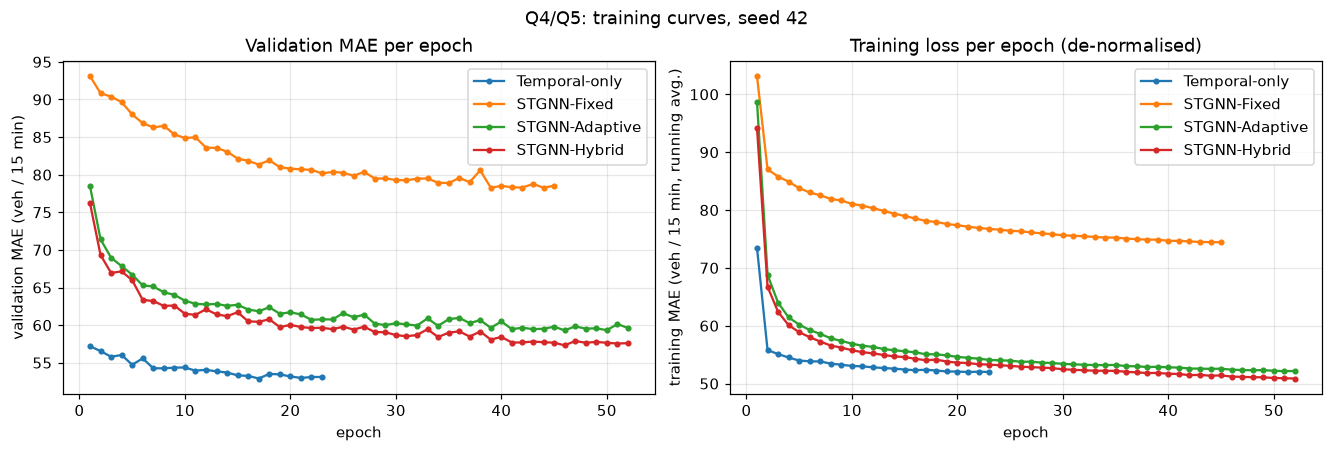

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, graph, adj in MODELS:
    h = RESULTS[name]['history']; lab = ('Temporal-only' if graph == 'none' else f'STGNN-{adj}')
    ax[0].plot([r['epoch'] for r in h], [r['val_mae'] for r in h], marker='o', ms=3, label=lab)
    ax[1].plot([r['epoch'] for r in h], [r['train_loss_norm'] * data['global_std'] for r in h], marker='o', ms=3, label=lab)
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('validation MAE (veh / 15 min)'); ax[0].set_title('Validation MAE per epoch'); ax[0].legend()
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('training MAE (veh / 15 min, running avg.)'); ax[1].set_title('Training loss per epoch (de-normalised)'); ax[1].legend()
fig.suptitle('Q4/Q5: training curves, seed 42'); fig.savefig(f'{FIG}/q4q5_training_curves.png', dpi=160); plt.show()

## Q5(b)-4 — Visualising the learned adjacency (adaptive model) next to the fixed road graph

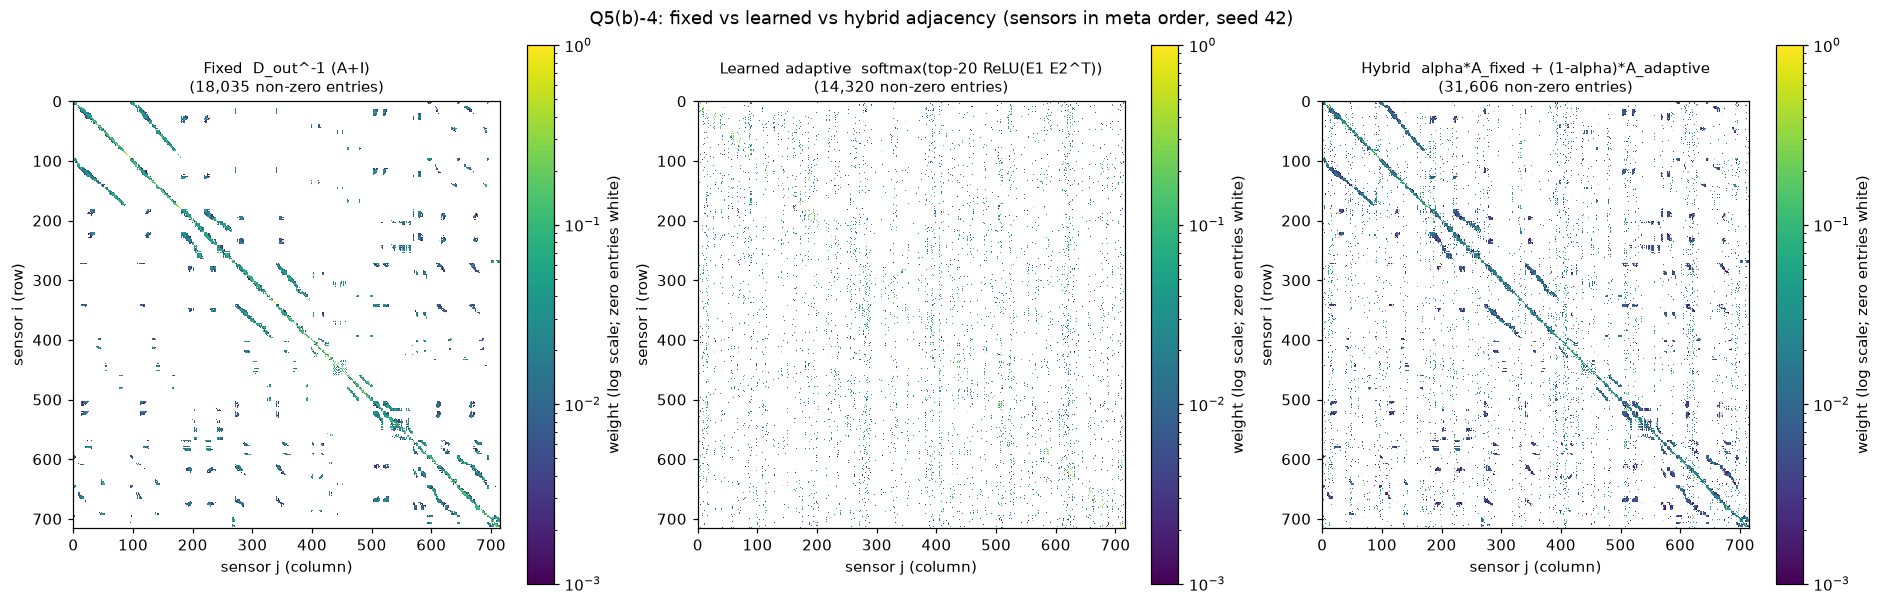

learned adaptive adjacency: nnz/row = 20.0, max weight 0.797, mean max-row weight 0.295, diagonal mass = 0.045
hybrid learned alpha = 0.2807 (initial 0.5)


In [14]:
from matplotlib.colors import LogNorm
Aad_l = np.load(f'{CKPT}/A_adaptive_stgnn_adaptive_seed42.npy'); Afx = A_fixed.numpy(); Ahy = np.load(f'{CKPT}/A_used_stgnn_hybrid_seed42.npy')
cmap = plt.get_cmap('viridis').copy(); cmap.set_bad('white'); cmap.set_under('lightgray')
fig, ax = plt.subplots(1, 3, figsize=(17, 5.4), constrained_layout=True)
for a_, M_, ttl in zip(ax, (Afx, Aad_l, Ahy), ('Fixed  D_out^-1 (A+I)', 'Learned adaptive  softmax(top-20 ReLU(E1 E2^T))', 'Hybrid  alpha*A_fixed + (1-alpha)*A_adaptive')):
    im = a_.imshow(np.where(M_ > 0, M_, np.nan), cmap=cmap, norm=LogNorm(vmin=1e-3, vmax=1.0), interpolation='nearest')
    a_.set_title(f'{ttl}\n({int((M_ > 0).sum()):,} non-zero entries)', fontsize=10); a_.set_xlabel('sensor j (column)'); a_.set_ylabel('sensor i (row)'); a_.grid(False)
    fig.colorbar(im, ax=a_, label='weight (log scale; zero entries white)')
fig.suptitle('Q5(b)-4: fixed vs learned vs hybrid adjacency (sensors in meta order, seed 42)'); fig.savefig(f'{FIG}/q5b_adjacency_fixed_vs_learned.png', dpi=160); plt.show()
print('learned adaptive adjacency: nnz/row = %.1f, max weight %.3f, mean max-row weight %.3f, diagonal mass = %.3f' % ((Aad_l > 0).sum(1).mean(), Aad_l.max(), Aad_l.max(1).mean(), np.diag(Aad_l).mean()))
print('hybrid learned alpha = %.4f (initial 0.5)' % RESULTS['stgnn_hybrid']['alpha'])